<a href="https://colab.research.google.com/github/sabbirpuspo/LearningforMe/blob/main/SkillMorph_15_CNN_DS_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 CNN
**SkillMorph Research Lab**

Topics: Convolution · Kernels · Pooling · Flatten · Mini Project

## 1️⃣ Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print('TF version:', tf.__version__)

TF version: 2.21.0


## 2️⃣ What is a CNN?

A CNN looks at **small pieces** of an image using a **filter (kernel)**.

```
Image → Conv → Pool → Conv → Pool → Flatten → Output
```

- **Conv** = find patterns (edges, shapes)
- **Pool** = make image smaller
- **Flatten** = convert to a list of numbers
- **Dense** = predict the class

## 3️⃣ Convolution – How it works

In [2]:
# Simple 4x4 image
image = np.array([[1,2,0,1],
                  [0,1,3,2],
                  [2,1,0,1],
                  [1,0,1,2]], dtype=float)

# 2x2 kernel (filter)
kernel = np.array([[1, 0],
                   [0,-1]], dtype=float)

print('Image:')
print(image)
print('\nKernel:')
print(kernel)

Image:
[[1. 2. 0. 1.]
 [0. 1. 3. 2.]
 [2. 1. 0. 1.]
 [1. 0. 1. 2.]]

Kernel:
[[ 1.  0.]
 [ 0. -1.]]


In [3]:
# Slide the kernel over the image (manual convolution)
output = np.zeros((3, 3))

for i in range(3):
    for j in range(3):
        patch = image[i:i+2, j:j+2]       # grab 2x2 patch
        output[i, j] = np.sum(patch * kernel)  # multiply + sum

print('Convolution Result:')
print(output)

Convolution Result:
[[ 0. -1. -2.]
 [-1.  1.  2.]
 [ 2.  0. -2.]]


## 4️⃣ Strides & Padding

| Option | Meaning |
|--------|---------|
| `padding='same'` | Output size = Input size |
| `padding='valid'` | Output gets smaller |
| `strides=2` | Skip every 2 pixels (faster, smaller output) |

In [4]:
x = tf.random.normal((1, 28, 28, 1))  # fake image

# same padding → keeps size
y1 = layers.Conv2D(8, 3, padding='same')(x)
# valid + stride 2 → reduces size
y2 = layers.Conv2D(8, 3, strides=2, padding='valid')(x)

print('Input :', x.shape)
print('Same  :', y1.shape)
print('Valid+stride2:', y2.shape)

Input : (1, 28, 28, 1)
Same  : (1, 28, 28, 8)
Valid+stride2: (1, 13, 13, 8)


## 5️⃣ Pooling

Pooling **shrinks** the feature map.
- **Max Pool** → keep the biggest number
- **Avg Pool** → take the average

In [5]:
fm = np.array([[1,3,2,0],
               [4,6,1,2],
               [0,1,5,3],
               [2,4,2,1]], dtype=float)

blocks = fm.reshape(2, 2, 2, 2)
max_pool = blocks.max(axis=(1,3))
avg_pool = blocks.mean(axis=(1,3))

print('Original:')
print(fm)
print('\nMax Pool:')
print(max_pool)
print('\nAvg Pool:')
print(avg_pool)

Original:
[[1. 3. 2. 0.]
 [4. 6. 1. 2.]
 [0. 1. 5. 3.]
 [2. 4. 2. 1.]]

Max Pool:
[[6. 2.]
 [4. 5.]]

Avg Pool:
[[3.5  1.25]
 [1.75 2.75]]


## 6️⃣ Flatten & Dense

After pooling, we **flatten** the 2D map into a 1D list,
then pass it to a **Dense** layer for prediction.

In [6]:
# Small example: 4x4x2 feature map → Flatten → Dense
model = keras.Sequential([
    keras.Input(shape=(4, 4, 2)),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(2,  activation='softmax')  # 2 classes
])


## 7️⃣ Mini Project – Leaf Disease (Healthy vs Diseased)

**Dataset:** PlantVillage subset from Kaggle

Folder structure needed:
```
PlantVillage_binary/
  train/  healthy/  diseased/
  test/   healthy/  diseased/
```

In [7]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
# Load images from folders
DATA = '/content/drive/MyDrive/PlantVillage_binary'

train_ds = keras.utils.image_dataset_from_directory(
    DATA + '/train',
    image_size=(128, 128),
    batch_size=32,
    label_mode='binary'
)

test_ds = keras.utils.image_dataset_from_directory(
    DATA + '/test',
    image_size=(128, 128),
    batch_size=32,
    label_mode='binary'
)

print('Classes:', train_ds.class_names)

Found 30 files belonging to 2 classes.
Found 10 files belonging to 2 classes.
Classes: ['diseased', 'healthy']


In [9]:
# Normalize pixel values from [0,255] to [0,1]
def normalize(img, label):
    return img / 255.0, label

train_ds = train_ds.map(normalize)
test_ds  = test_ds.map(normalize)

In [10]:
# Build a simple CNN
model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    layers.Conv2D(16, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(2),

    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(2),

    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1,  activation='sigmoid')   # binary: 0 or 1
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

for layer in model.layers:
    print(layer.name, layer.output.shape)

conv2d_2 (None, 128, 128, 16)
max_pooling2d (None, 64, 64, 16)
conv2d_3 (None, 64, 64, 32)
max_pooling2d_1 (None, 32, 32, 32)
flatten_1 (None, 32768)
dense_2 (None, 32)
dense_3 (None, 1)


In [11]:
# Train the model
history = model.fit(train_ds, epochs=15)

Epoch 1/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - accuracy: 0.5000 - loss: 0.7294
Epoch 2/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5000 - loss: 3.0205
Epoch 3/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.5000 - loss: 1.0580
Epoch 4/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5000 - loss: 0.7644
Epoch 5/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.5000 - loss: 0.7806
Epoch 6/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5000 - loss: 0.7321
Epoch 7/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5000 - loss: 0.6947
Epoch 8/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5000 - loss: 0.6729
Epoch 9/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.5000 - loss: 0.6665
Epoch 10/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.5000 - loss: 0.6645
Epoch 11/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.5000 - loss: 0.6576
Epoch 12/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.5000 - loss: 

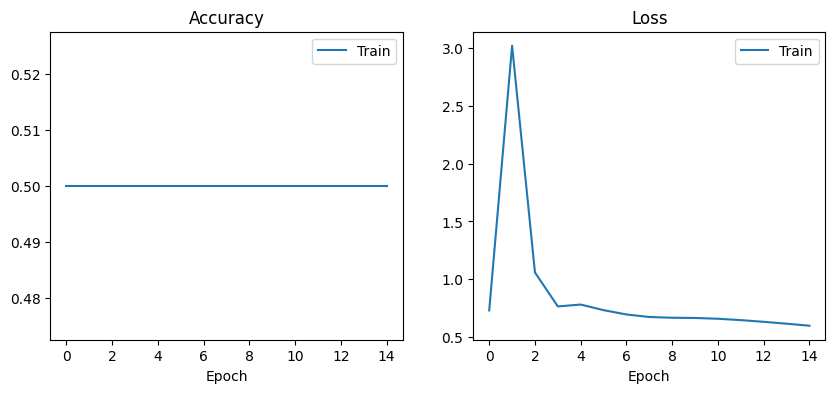

In [12]:
# Plot accuracy and loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(history.history['accuracy'], label='Train')
ax1.set_title('Accuracy')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(history.history['loss'], label='Train')
ax2.set_title('Loss')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.show()

In [13]:
# Evaluate on test set
loss, acc = model.evaluate(test_ds)
print(f'Test Accuracy: {acc:.2%}')
print(f'Test Loss    : {loss:.4f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.8000 - loss: 0.5808
Test Accuracy: 80.00%
Test Loss    : 0.5808


## 8️⃣ Homework – APTOS 2019 Retinal Images

**Download:** [APTOS 2019 on Kaggle](https://www.kaggle.com/c/aptos2019-blindness-detection)

Build **3 models** and compare them:

| Model | Kernel | Pool |
|-------|--------|------|
| A | 3×3 | MaxPool |
| B | 5×5 | MaxPool |
| C | 3×3 | AvgPool |

